In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("winequality-red.csv", sep=";")

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nQuality score distribution:")
display(df["quality"].value_counts().sort_index())

print("\nDescriptive statistics:")
display(df.describe().T)

First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Dataset shape: (1599, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


Quality score distribution:


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


Wine Quality Counts:


,Count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


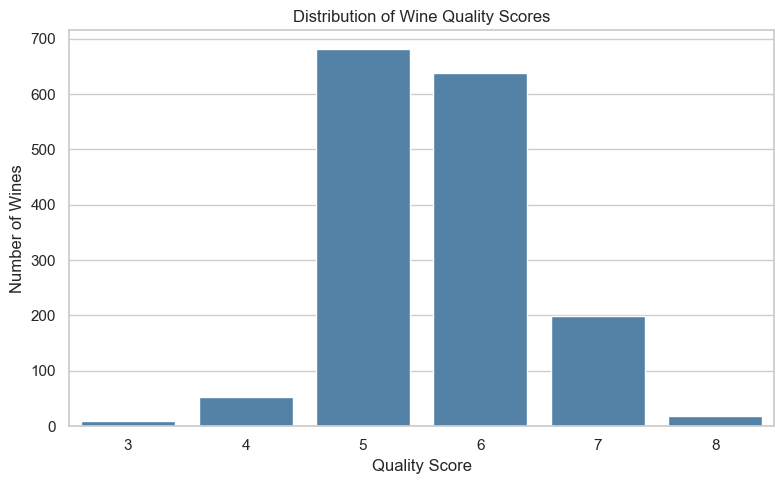

In [7]:
# Display the number of wines for each quality score
print("Wine Quality Counts:")
display(df["quality"].value_counts().sort_index().to_frame("Count"))

# Plot the quality score distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality", color="steelblue")

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()


Sample of Quality Categories:


,quality,quality_category
0,5,Low
1,5,Low
2,5,Low
3,6,Medium
4,5,Low
5,5,Low
6,5,Low
7,7,High
8,7,High
9,5,Low



Number of wines in each category:


,Number of Wines
quality_category,
Low,744
Medium,638
High,217


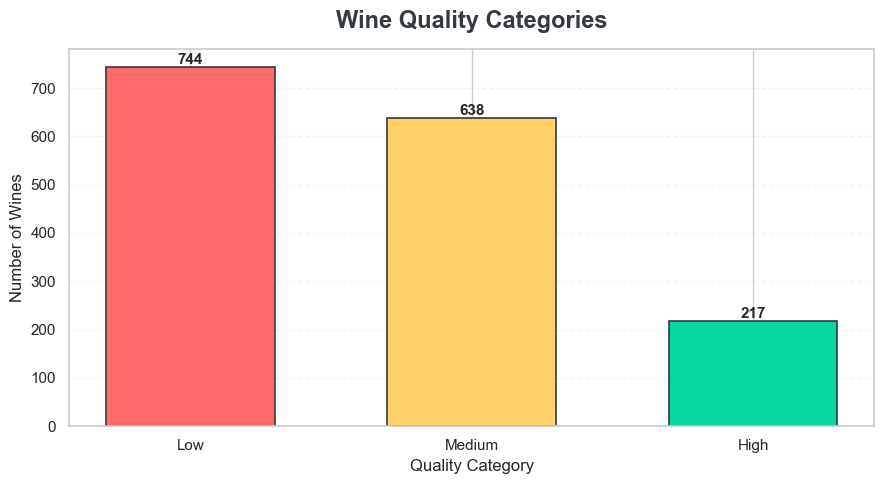

In [8]:

# Feature Engineering: Convert numerical quality scores into categories

def categorize_quality(score):
    if score <= 5:
        return "Low"
    elif score == 6:
        return "Medium"
    else:
        return "High"

df["quality_category"] = df["quality"].apply(categorize_quality)

# Display the original scores and their new categories
print("Sample of Quality Categories:")
display(df[["quality", "quality_category"]].head(10))

# Count wines in each category
category_counts = df["quality_category"].value_counts().reindex(
    ["Low", "Medium", "High"]
)

print("\nNumber of wines in each category:")
display(category_counts.to_frame("Number of Wines"))

# Creative, colorful visualization
category_colors = ["#FF6B6B", "#FFD166", "#06D6A0"]

plt.figure(figsize=(9, 5))
bars = plt.bar(
    category_counts.index,
    category_counts.values,
    color=category_colors,
    edgecolor="#343A40",
    linewidth=1.2,
    width=0.6
)

plt.title(
    "Wine Quality Categories",
    fontsize=17,
    fontweight="bold",
    color="#343A40",
    pad=15
)
plt.xlabel("Quality Category", fontsize=12)
plt.ylabel("Number of Wines", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.25)

# Add counts above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()



### Feature Engineering and Quality Categorization

The original wine quality score is numerical and ranges across several discrete values. For this classification task, the scores are grouped into three categories:

- **Low Quality:** Score less than or equal to 5
- **Medium Quality:** Score equal to 6
- **High Quality:** Score greater than or equal to 7

This grouping simplifies the prediction task while preserving meaningful quality levels. It also allows us to compare how well different classification algorithms distinguish between low-, medium-, and high-quality wines. The category distribution is visualized using distinct colors for better readability.


DATASET SPLIT SUMMARY
----------------------------------------
Total samples: 1599
Training samples: 1279
Testing samples: 320
Number of input features: 11

Training set category distribution:


,Count
quality_category,
Low,595
Medium,510
High,174



Testing set category distribution:


,Count
quality_category,
Low,149
Medium,128
High,43


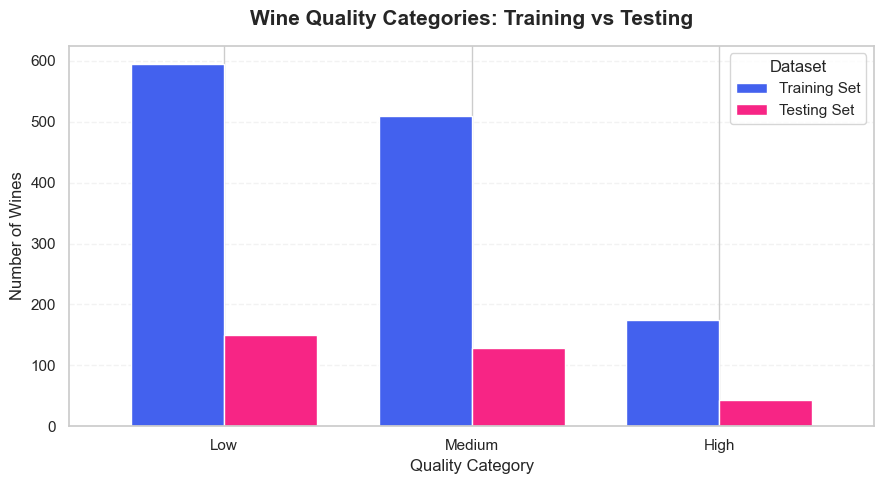

In [9]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["quality", "quality_category"])
y = df["quality_category"]

# Split into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATASET SPLIT SUMMARY")
print("-" * 40)
print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of input features:", X.shape[1])

print("\nTraining set category distribution:")
display(y_train.value_counts().reindex(["Low", "Medium", "High"]).to_frame("Count"))

print("\nTesting set category distribution:")
display(y_test.value_counts().reindex(["Low", "Medium", "High"]).to_frame("Count"))

# Visualize the split with different colors
split_counts = pd.DataFrame({
    "Training Set": y_train.value_counts(),
    "Testing Set": y_test.value_counts()
}).reindex(["Low", "Medium", "High"])

ax = split_counts.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#4361EE", "#F72585"],
    edgecolor="white",
    width=0.75
)

ax.set_title(
    "Wine Quality Categories: Training vs Testing",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Quality Category", fontsize=12)
ax.set_ylabel("Number of Wines", fontsize=12)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Dataset")
ax.grid(axis="y", linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()



### Train-Test Split

The dataset is divided into 80% training data and 20% testing data. The training data is used to build the classification models, while the testing data evaluates their performance on unseen samples.

Stratified sampling is applied to preserve approximately the same proportions of Low, Medium, and High quality wines in both sets. The `random_state=42` parameter ensures reproducibility, allowing the same split to be obtained when the code is rerun.

The chemical properties are used as input features, while the engineered quality category is the target variable. The original numerical quality score is excluded from the inputs to prevent target leakage.


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Define the three classification models
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),

    "SGD Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SGDClassifier(
            max_iter=2000,
            tol=1e-3,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "Support Vector Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            class_weight="balanced"
        ))
    ])
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"✓ {name} trained successfully!")

print("\nAll three models have been trained.")


✓ Random Forest trained successfully!
✓ SGD Classifier trained successfully!
✓ Support Vector Classifier trained successfully!

All three models have been trained.



### Model Training

Three classification algorithms are trained to predict wine quality categories: Random Forest, Stochastic Gradient Descent (SGD) Classifier, and Support Vector Classifier (SVC).

Random Forest is an ensemble learning algorithm, while SGD and SVC are trained using standardized input features. Class weighting is used to help address the imbalance between quality categories. All models use the same training and testing split to ensure a fair comparison.

The models will be evaluated using accuracy, precision, recall, F1-score, and confusion matrices. The final deployment choice will be based on the observed results rather than assuming one algorithm is best in advance.



CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

         Low       0.80      0.83      0.81       149
      Medium       0.69      0.71      0.70       128
        High       0.69      0.56      0.62        43

    accuracy                           0.74       320
   macro avg       0.73      0.70      0.71       320
weighted avg       0.74      0.74      0.74       320


CLASSIFICATION REPORT: SGD Classifier
              precision    recall  f1-score   support

         Low       0.70      0.74      0.72       149
      Medium       0.51      0.41      0.45       128
        High       0.23      0.33      0.27        43

    accuracy                           0.55       320
   macro avg       0.48      0.49      0.48       320
weighted avg       0.56      0.55      0.55       320


CLASSIFICATION REPORT: Support Vector Classifier
              precision    recall  f1-score   support

         Low       0.73      0.77      0.75       149
  

,Model,Accuracy,Macro F1-Score,Weighted F1-Score
0,Random Forest,74.38%,0.710,0.742
1,Support Vector Classifier,60.94%,0.576,0.604
2,SGD Classifier,55.31%,0.482,0.555


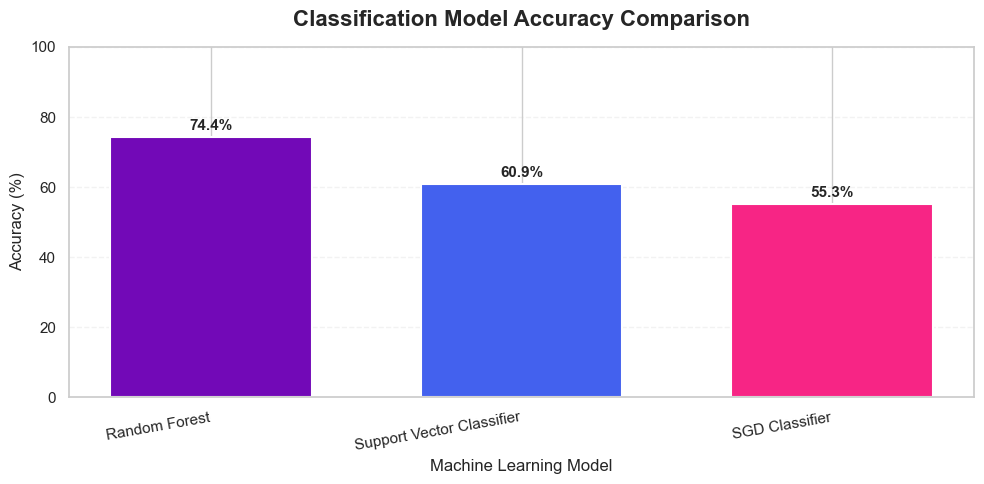

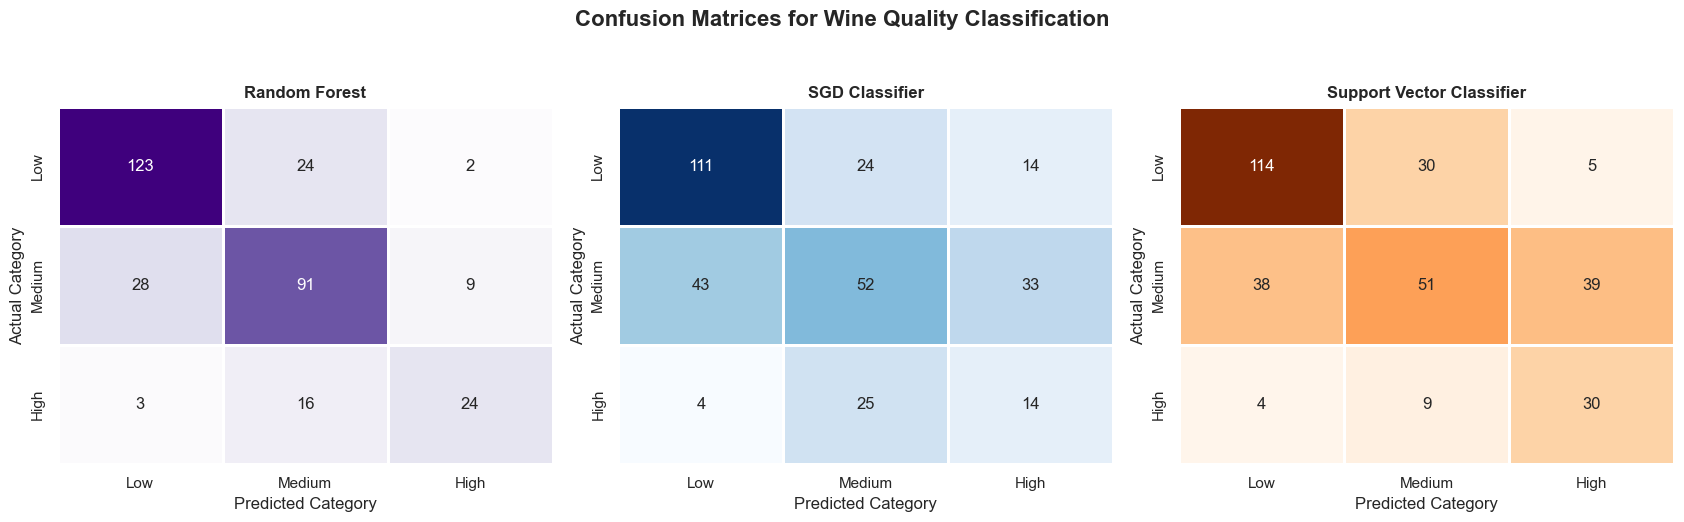

In [11]:
# Evaluating all classification models
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent order for the three quality categories
class_order = ["Low", "Medium", "High"]

results = []
predictions = {}

# Evaluate each trained model
for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test, y_pred,
        labels=class_order,
        average="macro",
        zero_division=0
    )
    weighted_f1 = f1_score(
        y_test, y_pred,
        labels=class_order,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1-Score": macro_f1,
        "Weighted F1-Score": weighted_f1
    })

    print("\n" + "=" * 65)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 65)

    print(classification_report(
        y_test,
        y_pred,
        labels=class_order,
        zero_division=0
    ))

# Create a model comparison table
results_df = pd.DataFrame(results).sort_values(
    by="Macro F1-Score",
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")
display(
    results_df.style
    .format({
        "Accuracy": "{:.2%}",
        "Macro F1-Score": "{:.3f}",
        "Weighted F1-Score": "{:.3f}"
    })
    .background_gradient(
        subset=["Accuracy", "Macro F1-Score", "Weighted F1-Score"],
        cmap="YlGnBu"
    )
)

# Colorful accuracy comparison chart
chart_colors = ["#7209B7", "#4361EE", "#F72585"]

plt.figure(figsize=(10, 5))
bars = plt.bar(
    results_df["Model"],
    results_df["Accuracy"] * 100,
    color=chart_colors[:len(results_df)],
    edgecolor="white",
    linewidth=1.5,
    width=0.65
)

plt.title(
    "Classification Model Accuracy Comparison",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.25)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()

# Draw a separate confusion matrix for each model
matrix_colors = ["Purples", "Blues", "Oranges"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, y_pred), cmap in zip(
    axes,
    predictions.items(),
    matrix_colors
):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_order
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=cmap,
        xticklabels=class_order,
        yticklabels=class_order,
        linewidths=1,
        linecolor="white",
        cbar=False,
        ax=ax
    )

    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Category")
    ax.set_ylabel("Actual Category")

fig.suptitle(
    "Confusion Matrices for Wine Quality Classification",
    fontsize=16,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()


Random Forest Feature Importance:


,Feature,Importance
10,alcohol,0.1668
9,sulphates,0.1158
1,volatile acidity,0.1102
6,total sulfur dioxide,0.0942
2,citric acid,0.0897
7,density,0.0827
4,chlorides,0.0771
0,fixed acidity,0.0702
8,pH,0.0671
3,residual sugar,0.0646


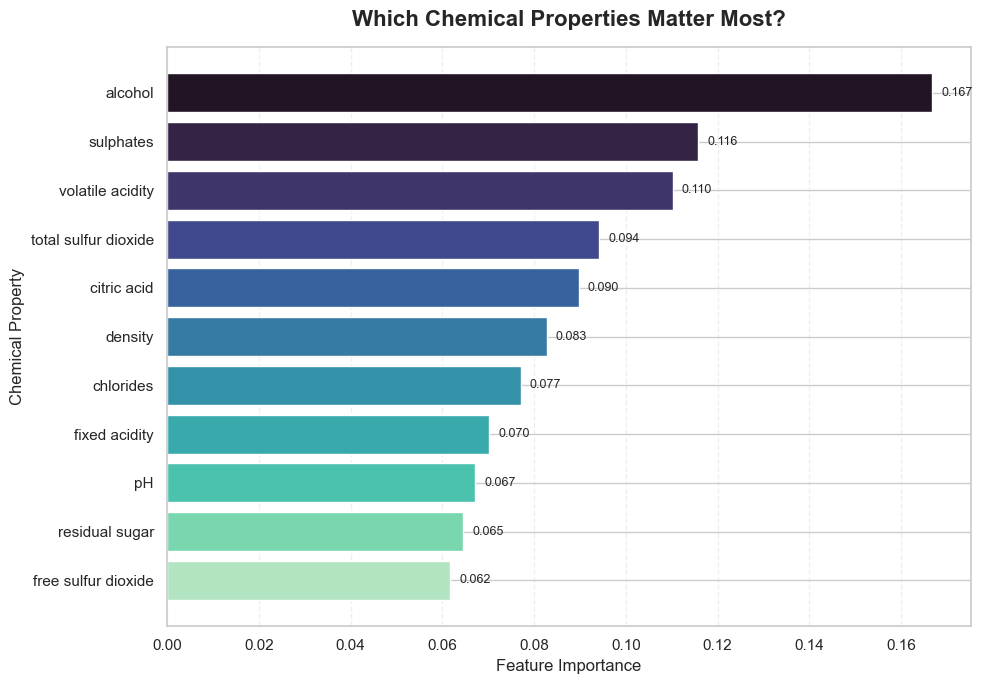

In [12]:

#  Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance from the trained Random Forest model
rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Random Forest Feature Importance:")
display(
    importance_df.style
    .format({"Importance": "{:.4f}"})
    .background_gradient(subset=["Importance"], cmap="YlOrRd")
)

# Colorful horizontal bar chart
plt.figure(figsize=(10, 7))

colors = sns.color_palette("mako", n_colors=len(importance_df))

bars = plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    color=colors,
    edgecolor="white",
    linewidth=1
)

plt.gca().invert_yaxis()

plt.title(
    "Which Chemical Properties Matter Most?",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Chemical Property", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()



### Feature Importance Analysis

Random Forest feature importance estimates how much each chemical property contributes to the model's decision-making process. Features with higher importance values contribute more to the model's predictions within this trained model.

The horizontal bar chart ranks the chemical properties from most to least important. These results can help identify which measurements are most useful for distinguishing between Low, Medium, and High wine quality categories.

Feature importance indicates predictive usefulness, not proof that a chemical property directly causes a particular wine quality.


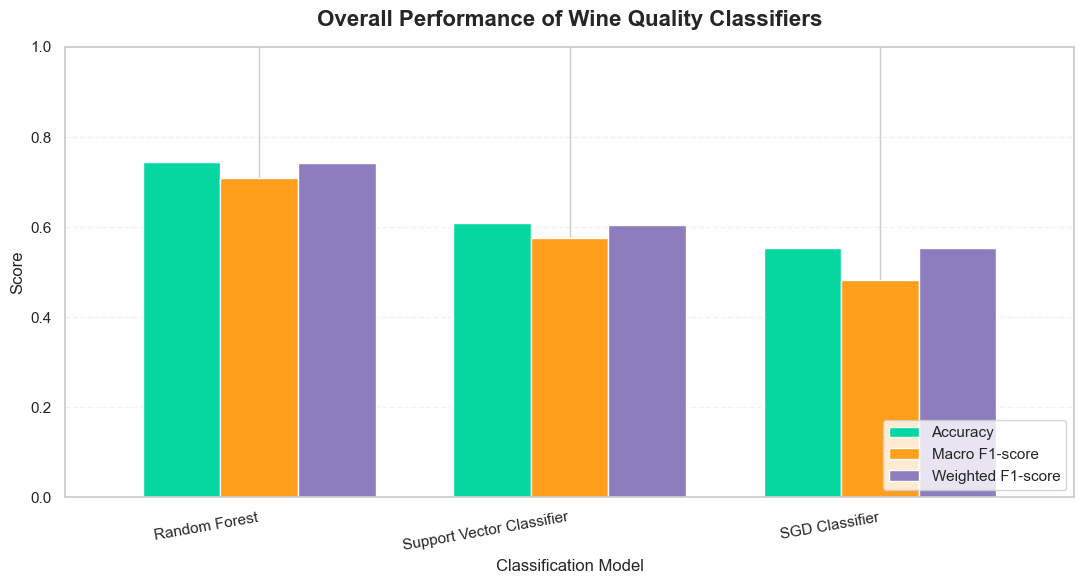

Best model by macro F1-score:
Random Forest
Macro F1-score: 0.710
Accuracy: 74.38%


In [13]:

#  Compare Accuracy, Macro F1, and Weighted F1

comparison = results_df.set_index("Model")[
    ["Accuracy", "Macro F1-Score", "Weighted F1-Score"]
]

ax = comparison.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#06D6A0", "#FF9F1C", "#8E7DBE"],
    edgecolor="white",
    width=0.75
)

ax.set_title(
    "Overall Performance of Wine Quality Classifiers",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Classification Model", fontsize=12)
ax.set_ylabel("Score", fontsize=12)
ax.set_ylim(0, 1.0)
ax.legend(
    ["Accuracy", "Macro F1-score", "Weighted F1-score"],
    loc="lower right"
)
ax.grid(axis="y", linestyle="--", alpha=0.25)
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()

print("Best model by macro F1-score:")
print(results_df.iloc[0]["Model"])
print(f"Macro F1-score: {results_df.iloc[0]['Macro F1-Score']:.3f}")
print(f"Accuracy: {results_df.iloc[0]['Accuracy']:.2%}")



# Conclusion

This project developed and compared three machine learning classification algorithms—Random Forest, Support Vector Classifier (SVC), and Stochastic Gradient Descent (SGD)—to predict wine quality categories from physicochemical properties.

The original wine quality scores were grouped into Low (score ≤ 5), Medium (score = 6), and High (score ≥ 7). The dataset was split into training and testing sets using stratified sampling, and feature scaling was applied to the SGD and SVC models.

## Key Findings

- **Random Forest:** Achieved approximately 74.38% accuracy and a macro F1-score of 0.710.
- **Support Vector Classifier:** Achieved approximately 60.94% accuracy and a macro F1-score of 0.576.
- **SGD Classifier:** Achieved approximately 55.31% accuracy and a macro F1-score of 0.482.

Random Forest performed best among the three models on this test set, based on both accuracy and macro F1-score. Its feature importance analysis also helped identify the physicochemical properties most useful for predicting wine quality categories.

## Challenges and Limitations

The dataset contains imbalanced quality categories, with fewer examples in some groups. The models also have difficulty distinguishing certain categories, particularly High-quality wines. Grouping the original scores simplifies classification but loses some detail about the individual quality scores.

## Future Improvements

Future work could explore hyperparameter tuning, cross-validation, alternative class-balancing methods, and additional classification algorithms. Performance could also be improved by collecting more examples of underrepresented quality categories.

## Final Conclusion

Random Forest is the most suitable candidate for further development among the three models evaluated in this experiment. However, further validation on additional data would be necessary before deploying it in a real-world wine quality assessment system.
